In [1]:
import sys

print(sys.executable)

e:\DRIV F\machin learning\project\Nonlinear Regression\.venv\Scripts\python.exe


In [2]:
import pandas as pd

df = pd.read_csv("chwirut1_nist.csv")

display(df.head())

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

df.info()

display(df.describe())

print("Missing values:")
print(df.isna().sum())

,Metal_Distance,Ultrasonic_Response,Tag
0,0.500,92.9,1
1,0.625,78.7,1
2,0.750,64.2,1
3,0.875,64.9,1
4,1.000,57.1,1


Shape: (214, 3)
Columns: ['Metal_Distance', 'Ultrasonic_Response', 'Tag']
<class 'pandas.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Metal_Distance       214 non-null    float64
 1   Ultrasonic_Response  214 non-null    float64
 2   Tag                  214 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 5.1 KB


,Metal_Distance,Ultrasonic_Response,Tag
count,214.000000,214.000000,214.000000
mean,2.544393,30.261495,16.214953
std,1.645679,23.679793,11.905755
min,0.500000,3.750000,1.000000
25%,1.000000,11.875000,4.000000
50%,2.250000,21.110000,17.000000
75%,3.250000,47.775000,27.000000
max,6.000000,92.900000,40.000000


Missing values:
Metal_Distance         0
Ultrasonic_Response    0
Tag                    0
dtype: int64


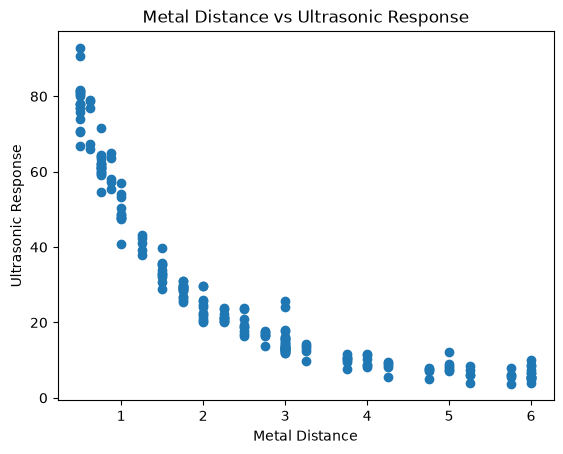

In [3]:
import matplotlib.pyplot as plt

plt.scatter(df["Metal_Distance"], df["Ultrasonic_Response"])

plt.xlabel("Metal Distance")
plt.ylabel("Ultrasonic Response")
plt.title("Metal Distance vs Ultrasonic Response")

plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X = df[["Metal_Distance"]]
y = df["Ultrasonic_Response"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))
print("Intercept:", linear_model.intercept_)
print("Slope:", linear_model.coef_[0])

Training samples: 171
Test samples: 43
Intercept: 61.190450294991436
Slope: -12.031260029884063


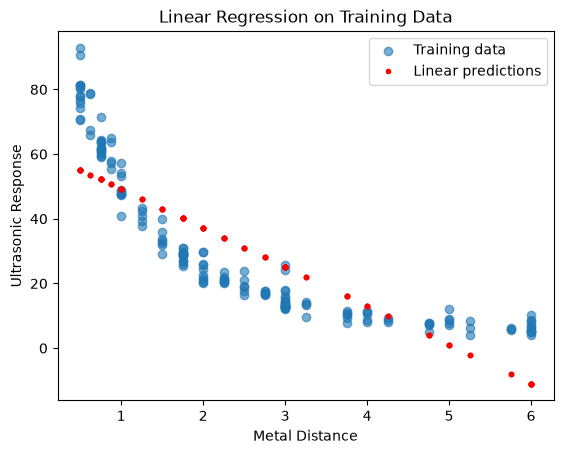

In [5]:
linear_train_pred = linear_model.predict(X_train)

plt.scatter(
    X_train["Metal_Distance"],
    y_train,
    label="Training data",
    alpha=0.6
)

plt.plot(
    X_train["Metal_Distance"],
    linear_train_pred,
    color="red",
    linestyle="None",
    marker=".",
    label="Linear predictions"
)

plt.xlabel("Metal Distance")
plt.ylabel("Ultrasonic Response")
plt.title("Linear Regression on Training Data")
plt.legend()

plt.show()

In [6]:
import numpy as np

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

linear_test_pred = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_test_pred)
linear_mse = mean_squared_error(y_test, linear_test_pred)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_test, linear_test_pred)

linear_results = {
    "Model": "Linear Regression",
    "MAE": linear_mae,
    "MSE": linear_mse,
    "RMSE": linear_rmse,
    "R2": linear_r2
}

display(pd.DataFrame([linear_results]))

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,11.070075,151.334783,12.30182,0.71715


In [7]:
def nonlinear_model(x, alpha, A, B):
    numerator = np.exp(-alpha * x)
    denominator = A + B * x

    return numerator / denominator

In [8]:
from scipy.optimize import curve_fit

In [9]:
initial_guess = [0.1, 0.01, 0.01]

In [10]:
#                 alpha    A      B
initial_guess = [0.1,    0.01,  0.01]

In [11]:
parameters, covariance = curve_fit(
    nonlinear_model,
    X_train["Metal_Distance"].to_numpy(),
    y_train.to_numpy(),
    p0=initial_guess
)

alpha_fit, A_fit, B_fit = parameters

print("alpha:", alpha_fit)
print("A:", A_fit)
print("B:", B_fit)

alpha: 0.18072708563454867
A: 0.005906848946055625
B: 0.010868345322392196


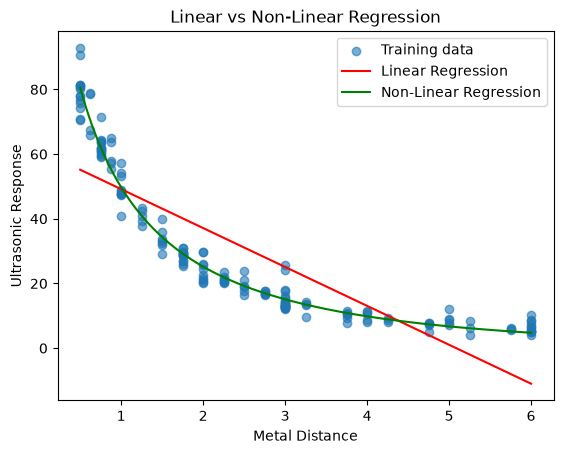

In [12]:
x_grid = np.linspace(
    X_train["Metal_Distance"].min(),
    X_train["Metal_Distance"].max(),
    300
)

linear_curve = (
    linear_model.intercept_
    + linear_model.coef_[0] * x_grid
)

nonlinear_curve = nonlinear_model(
    x_grid,
    alpha_fit,
    A_fit,
    B_fit
)

plt.scatter(
    X_train["Metal_Distance"],
    y_train,
    alpha=0.6,
    label="Training data"
)

plt.plot(x_grid, linear_curve, color="red", label="Linear Regression")
plt.plot(x_grid, nonlinear_curve, color="green", label="Non-Linear Regression")

plt.xlabel("Metal Distance")
plt.ylabel("Ultrasonic Response")
plt.title("Linear vs Non-Linear Regression")
plt.legend()

plt.show()

In [13]:
nonlinear_test_pred = nonlinear_model(
    X_test["Metal_Distance"].to_numpy(),
    alpha_fit,
    A_fit,
    B_fit
)

nonlinear_residuals = y_test.to_numpy() - nonlinear_test_pred

prediction_results = pd.DataFrame({
    "Metal_Distance": X_test["Metal_Distance"].to_numpy(),
    "Actual": y_test.to_numpy(),
    "Predicted": nonlinear_test_pred,
    "Residual": nonlinear_residuals
})

display(prediction_results.head(10))

,Metal_Distance,Actual,Predicted,Residual
0,2.25,23.7750,21.932570,1.842430
1,3.00,15.6400,15.098677,0.541323
2,5.25,5.9625,6.149363,-0.186863
3,3.00,13.3100,15.098677,-1.788677
4,5.00,7.3100,6.723716,0.586284
5,1.50,35.2000,34.334494,0.865506
6,5.25,7.3500,6.149363,1.200637
7,3.00,11.8100,15.098677,-3.288677
8,0.50,78.0000,80.557028,-2.557028
9,5.75,3.7500,5.171714,-1.421714


In [14]:
nonlinear_mae = mean_absolute_error(y_test, nonlinear_test_pred)
nonlinear_mse = mean_squared_error(y_test, nonlinear_test_pred)
nonlinear_rmse = np.sqrt(nonlinear_mse)
nonlinear_r2 = r2_score(y_test, nonlinear_test_pred)

nonlinear_results = {
    "Model": "Non-Linear Regression",
    "MAE": nonlinear_mae,
    "MSE": nonlinear_mse,
    "RMSE": nonlinear_rmse,
    "R2": nonlinear_r2
}

comparison = pd.DataFrame([
    linear_results,
    nonlinear_results
])

display(comparison)

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,11.070075,151.334783,12.301820,0.717150
1,Non-Linear Regression,2.096731,10.294767,3.208546,0.980759


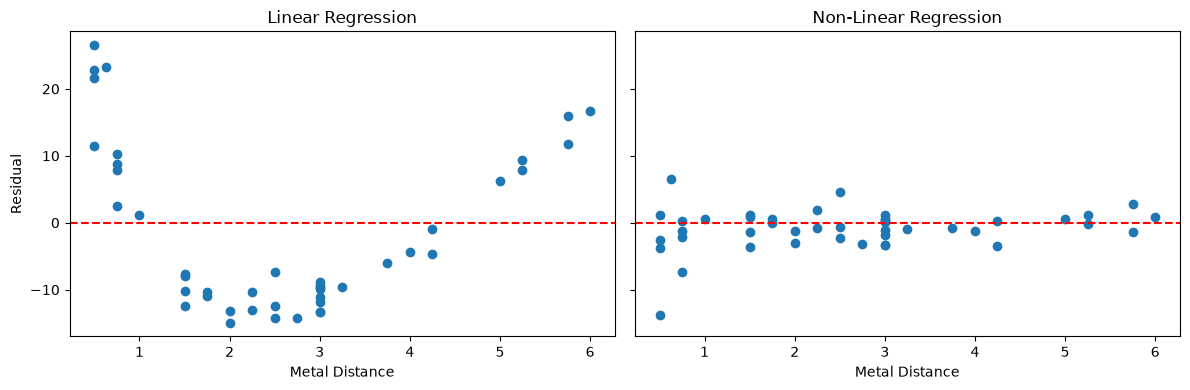

In [15]:
linear_residuals = y_test.to_numpy() - linear_test_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

axes[0].scatter(X_test["Metal_Distance"], linear_residuals)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Linear Regression")
axes[0].set_xlabel("Metal Distance")
axes[0].set_ylabel("Residual")

axes[1].scatter(X_test["Metal_Distance"], nonlinear_residuals)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Non-Linear Regression")
axes[1].set_xlabel("Metal Distance")

plt.tight_layout()
plt.show()

In [16]:
new_distance = 2.5

predicted_response = nonlinear_model(
    new_distance,
    alpha_fit,
    A_fit,
    B_fit
)

print(f"Metal Distance: {new_distance}")
print(f"Predicted Ultrasonic Response: {predicted_response:.2f}")

Metal Distance: 2.5
Predicted Ultrasonic Response: 19.24


In [17]:
outside_distance = 8.0

outside_prediction = nonlinear_model(
    outside_distance,
    alpha_fit,
    A_fit,
    B_fit
)

print(f"Metal Distance: {outside_distance}")
print(f"Predicted Ultrasonic Response: {outside_prediction:.2f}")

Metal Distance: 8.0
Predicted Ultrasonic Response: 2.54
